In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('placement.csv')
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


In [3]:
df.shape

(1000, 3)

In [4]:
df['placement_exam_marks'].describe()

count    1000.000000
mean       32.225000
std        19.130822
min         0.000000
25%        17.000000
50%        28.000000
75%        44.000000
max       100.000000
Name: placement_exam_marks, dtype: float64

<Axes: ylabel='placement_exam_marks'>

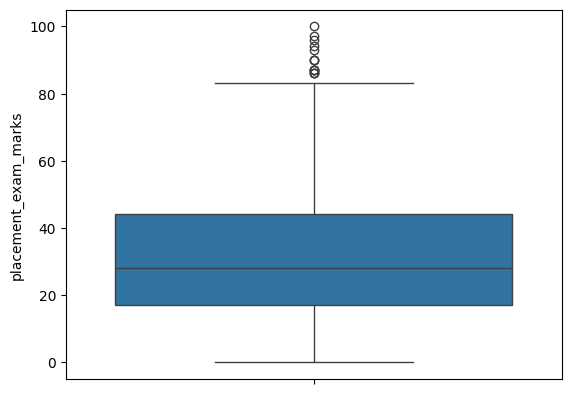

In [5]:
sns.boxplot(df['placement_exam_marks'])

In [10]:
# finding IQR

q1 = df['placement_exam_marks'].quantile(0.25)
q3 = df['placement_exam_marks'].quantile(0.75)
print(q1)
print(q3)

17.0
44.0


In [12]:
iqr = q3 - q1
iqr

np.float64(27.0)

In [13]:
upper_fence = q3 + 1.5*iqr
lower_fence = q1 - 1.5*iqr
print(upper_fence)
print(lower_fence)

84.5
-23.5


**Finding Outliers**

In [18]:
df[(df['placement_exam_marks'] > upper_fence) | (df['placement_exam_marks'] < lower_fence)]

,cgpa,placement_exam_marks,placed
9,7.75,94.0,1
40,6.60,86.0,1
61,7.51,86.0,0
134,6.33,93.0,0
162,7.80,90.0,0
283,7.09,87.0,0
290,8.38,87.0,0
311,6.97,87.0,1
324,6.64,90.0,0
630,6.56,96.0,1


In [17]:
df[df['placement_exam_marks'] < lower_fence]

,cgpa,placement_exam_marks,placed


**Trimming**

In [20]:
new_df = df[df['placement_exam_marks'] < upper_fence]
new_df

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


In [21]:
new_df.shape

(985, 3)

<Axes: ylabel='placement_exam_marks'>

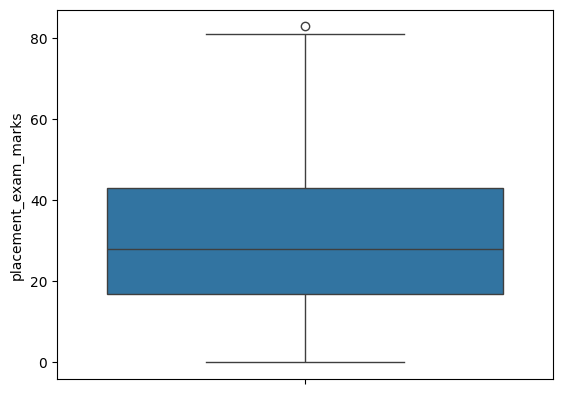

In [24]:
sns.boxplot(new_df['placement_exam_marks'])

In [28]:
#new_df_cap = df.copy()

new_df_cap['placement_exam_marks'] = np.where(new_df_cap['placement_exam_marks'] > upper_fence, upper_fence,
                                      np.where(new_df_cap['placement_exam_marks'] < lower_fence, lower_fence,
                                               new_df_cap['placement_exam_marks']))

In [29]:
new_df_cap.shape

(1000, 3)

<Axes: ylabel='placement_exam_marks'>

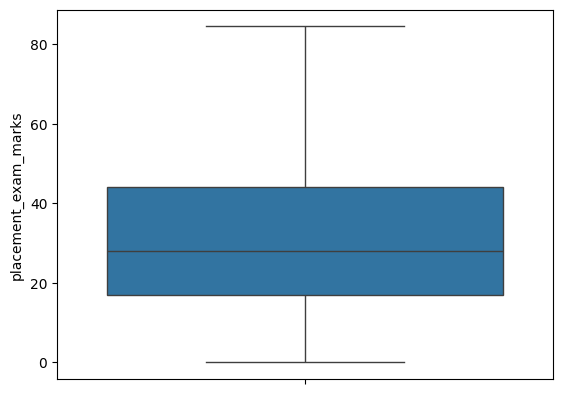

In [30]:
sns.boxplot(new_df_cap['placement_exam_marks'])

In [35]:
new_df_cap.shape

(1000, 3)

C:\Users\Abhishek\AppData\Local\Temp\ipykernel_12380\1750106886.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['placement_exam_marks'], color = 'red')
C:\Users\Abhishek\AppData\Local\Temp\ipykernel_12380\1750106886.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(new_df_cap['placement

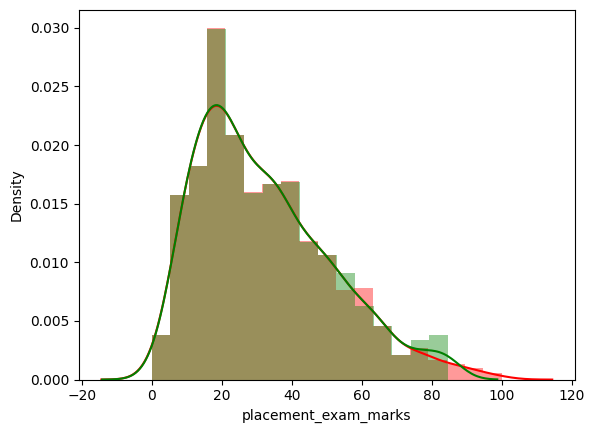

In [33]:
sns.distplot(df['placement_exam_marks'], color = 'red')
sns.distplot(new_df_cap['placement_exam_marks'], color= 'green')
plt.show()